# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 8: Particle Swarm Optimization (PSO)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Yashvi Shivhare* |
| **Enrollment No.** | *2023BTCSE021* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Particle Swarm Optimization (PSO) algorithm for solving an optimization problem using Python.

### 2. Theory: Swarm Intelligence with PSO

In PSO, particles fly through the search space guided by their personal best ($\mathbf{p}_i$) and the swarm's global best ($\mathbf{g}$):
$$\mathbf{v}_i^{(t+1)} = w \mathbf{v}_i^{(t)} + c_1 r_1 (\mathbf{p}_i - \mathbf{x}_i^{(t)}) + c_2 r_2 (\mathbf{g} - \mathbf{x}_i^{(t)})$$
$$\mathbf{x}_i^{(t+1)} = \mathbf{x}_i^{(t)} + \mathbf{v}_i^{(t+1)}$$

### 3. Step 1: Minimizing 2D Sphere Function with PSO

Best Position: [-1.1e-05 -2.8e-05], Best Value: 0.00000000


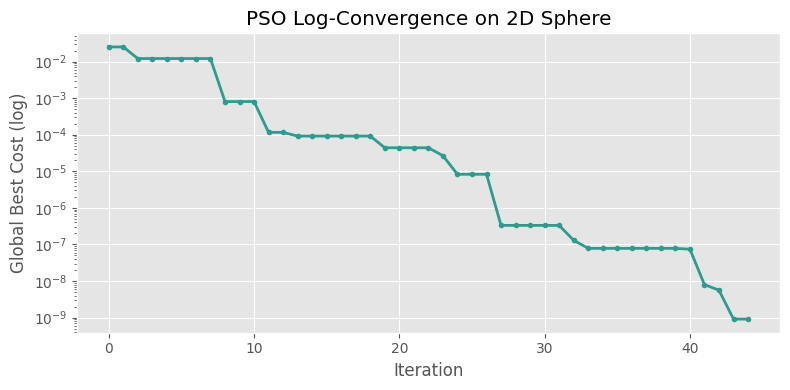

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(808)
plt.style.use('ggplot')

def sphere(x):
    return np.sum(x ** 2, axis=-1)

n_p, dim, iters = 30, 2, 45
w, c1, c2 = 0.65, 1.4, 1.4
pos = np.random.uniform(-8, 8, (n_p, dim))
vel = np.random.uniform(-1, 1, (n_p, dim))
pbest = pos.copy()
pbest_val = sphere(pos)
gbest = pbest[np.argmin(pbest_val)].copy()
gbest_val = np.min(pbest_val)

hist = []
for _ in range(iters):
    r1, r2 = np.random.rand(n_p, dim), np.random.rand(n_p, dim)
    vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)
    pos = np.clip(pos + vel, -8, 8)
    vals = sphere(pos)
    imp = vals < pbest_val
    pbest[imp] = pos[imp]
    pbest_val[imp] = vals[imp]
    if np.min(pbest_val) < gbest_val:
        gbest_val = np.min(pbest_val)
        gbest = pbest[np.argmin(pbest_val)].copy()
    hist.append(gbest_val)

print(f"Best Position: {np.round(gbest, 6)}, Best Value: {gbest_val:.8f}")

plt.figure(figsize=(8, 4))
plt.semilogy(hist, marker='o', markersize=3, color='#2a9d8f', linewidth=2)
plt.title("PSO Log-Convergence on 2D Sphere")
plt.xlabel("Iteration")
plt.ylabel("Global Best Cost (log)")
plt.tight_layout()
plt.show()

### 4. Conclusion
PSO converged smoothly to the global minimum $(0, 0)$ of the 2D Sphere function.